# Forward Propagation Implementation: Problem 2

## Load the MNIST Test Data

In [1]:
import gzip
import numpy as np

key_file = {
    "test_img": "model/t10k-images-idx3-ubyte.gz",
    "test_label": "model/t10k-labels-idx1-ubyte.gz",
}
img_size = 28 * 28


def load_images(file_name):
    with gzip.open(file_name, "rb") as file:
        images = np.frombuffer(file.read(), np.uint8, offset=16)
    return images.reshape((-1, img_size))


def load_labels(file_name):
    with gzip.open(file_name, "rb") as file:
        return np.frombuffer(file.read(), np.uint8, offset=8)


X_test = load_images(key_file["test_img"])
y_test = load_labels(key_file["test_label"])

print("Images:", X_test.shape)
print("Labels:", y_test.shape)
y_test[:10]

Images: (10000, 784)
Labels: (10000,)


array([7, 2, 1, 0, 4, 1, 4, 9, 5, 9], dtype=uint8)

## Show the digit being tested

Label: 6


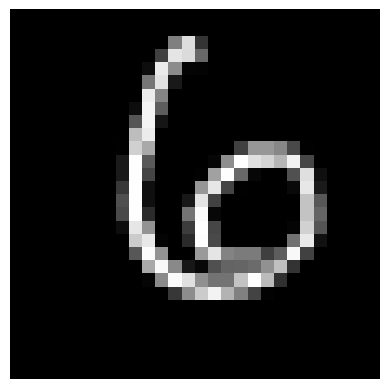

In [3]:
import matplotlib.pyplot as plt

n = 100
print("Label:", y_test[n])
plt.imshow(X_test[n].reshape((28, 28)), cmap="gray")
plt.axis("off")
plt.show()

## Load the Neural Network

In [4]:
import pickle


def init_network(model_file_name):
    with open(model_file_name, "rb") as file:
        return pickle.load(file)


network = init_network("model/sample_weight.pkl")
print(network.keys())
print("W3 shape:", network["W3"].shape)

dict_keys(['b2', 'W1', 'b1', 'W2', 'W3', 'b3'])
W3 shape: (100, 10)


## Define Forward Propagation

In [5]:
def sigmoid(values):
    return 1 / (1 + np.exp(-values))


def softmax(values):
    shifted = values - np.max(values)
    probabilities = np.exp(shifted)
    return probabilities / np.sum(probabilities)


def predict(network, image):
    w1, w2, w3 = network["W1"], network["W2"], network["W3"]
    b1, b2, b3 = network["b1"], network["b2"], network["b3"]

    first_layer = sigmoid(np.dot(image, w1) + b1)
    second_layer = sigmoid(np.dot(first_layer, w2) + b2)
    output_layer = np.dot(second_layer, w3) + b3
    return softmax(output_layer)


print("Flattened test image shape:", X_test[0].reshape((-1,)).shape)

Flattened test image shape: (784,)


## Evaluate the MNIST Test Set

Probabilities: [1.64981876e-04 2.80873699e-04 4.46585908e-02 6.82161058e-05
 1.76548295e-03 7.07103878e-04 9.52186075e-01 3.33890052e-05
 1.32181742e-04 3.10497406e-06]
True label: 6
Prediction: 6
Certainty: 0.9521860749660173
MNIST test accuracy: 93.52%


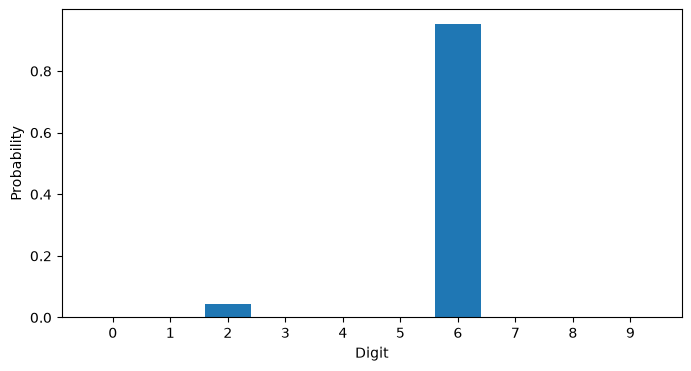

In [6]:
test_index = 100
test_image = X_test[test_index] / 255.0
probabilities = predict(network, test_image)

print("Probabilities:", probabilities)
print("True label:", y_test[test_index])
print("Prediction:", np.argmax(probabilities))
print("Certainty:", np.max(probabilities))

mnist_predictions = np.array([np.argmax(predict(network, image / 255.0)) for image in X_test])
mnist_accuracy = np.mean(mnist_predictions == y_test)
print(f"MNIST test accuracy: {mnist_accuracy:.2%}")

plt.figure(figsize=(8, 4))
plt.bar(np.arange(10), probabilities)
plt.xticks(np.arange(10))
plt.xlabel("Digit")
plt.ylabel("Probability")
plt.show()

## Evaluate the Custom Digit Images

Custom digit accuracy: 33.00% (100 images)
Image: digits/0/0_0.png
Expected: 0
Prediction: 7
Certainty: 0.9520242


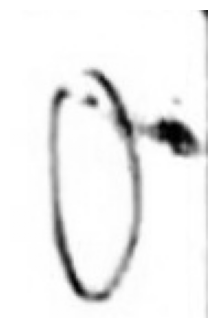

In [7]:
from pathlib import Path
from PIL import Image


def prepare_custom_image(image_path):
    image = Image.open(image_path).convert("L")
    side = max(image.size)
    canvas = Image.new("L", (side, side), color=255)
    offset = ((side - image.width) // 2, (side - image.height) // 2)
    canvas.paste(image, offset)
    image = canvas.resize((28, 28))
    image = Image.fromarray(255 - np.asarray(image, dtype=np.uint8))
    return np.asarray(image, dtype=np.float32).reshape(-1) / 255.0


custom_paths = sorted(Path("digits").glob("*/[0-9]_[0-9].png"))
custom_results = []

for image_path in custom_paths:
    expected_digit = int(image_path.parent.name)
    image_vector = prepare_custom_image(image_path)
    probabilities = predict(network, image_vector)
    predicted_digit = int(np.argmax(probabilities))
    custom_results.append((image_path, expected_digit, predicted_digit, np.max(probabilities)))

custom_accuracy = np.mean([expected == predicted for _, expected, predicted, _ in custom_results])
print(f"Custom digit accuracy: {custom_accuracy:.2%} ({len(custom_results)} images)")

preview_path, expected_digit, predicted_digit, certainty = custom_results[0]
preview_image = Image.open(preview_path).convert("L")
print("Image:", preview_path)
print("Expected:", expected_digit)
print("Prediction:", predicted_digit)
print("Certainty:", certainty)

plt.figure(figsize=(8, 4))
plt.imshow(preview_image, cmap="gray")
plt.axis("off")
plt.show()